# Unsupervised Color-Based Clustering of TV Show Posters with IMDb Metadata Analysis

In [1]:
import os
import random
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import warnings
warnings.filterwarnings('ignore')

In [2]:
def get_random_images(filepath, n):
    # Get n images in the folder
    all_images = [f for f in os.listdir(filepath) if f.startswith('tt')]
    return random.sample(all_images, min(n, len(all_images)))

In [3]:
def extract_imdb_id(filename):
    # Extract the IMDB ID from the filename
    return filename.split('.')[0]

In [4]:
def get_imdb_data(imdb_id):
    # Get the IMDB data for a given IMDB ID
    url = f'https://www.imdb.com/title/{imdb_id}/'
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"}

    
    try:
        response = requests.get(url, headers=headers)
        soup = BeautifulSoup(response.text, 'html.parser')
        script = soup.find('script', {'type': 'application/ld+json'})
        if not script:
            return None
        
        import json
        data = json.loads(script.string)
        
        show_data = {
            'imdb_id': imdb_id,
            'title': data.get('name', ''),
            'rating': data.get('aggregateRating', {}).get('ratingValue', 0),
            'rating_count': data.get('aggregateRating', {}).get('ratingCount', 0),
            'content_rating': data.get('contentRating', ''),
            'date_published': data.get('datePublished', ''),
            'genres': data.get('genre', [])  
        }
        
        return show_data
    except Exception as e:
        print(f"Error processing {imdb_id}: {str(e)}")
        return None

In [5]:
def extract_color_features(image_path):
    # Extract color features from an image
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    img_resized = cv2.resize(img, (224, 336))
    
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Extract RGBW features
    features = {}
    r, g, b = cv2.split(img_rgb)
    w = (r + g + b) / 3  
    features = np.array([r.mean(), g.mean(), b.mean(), w.mean()])
    
    return features

In [6]:
def create_dataset(image_folder):
    """Create datasets from images and their analysis."""
    images = get_random_images(image_folder, 100)
    imdb_data = []
    feature_data = []
    
    for img in images:
        imdb_id = extract_imdb_id(img)
        show_data = get_imdb_data(imdb_id)
        
        if show_data:
            img_path = os.path.join(image_folder, img)
            features = extract_color_features(img_path)

            if features is not None:  
                features_with_id = np.append(features, imdb_id)  
                feature_data.append(features_with_id)
                imdb_data.append(show_data)
    
    # Define column names for the feature DataFrame
    feature_columns = ['r_mean', 'g_mean', 'b_mean', 'w_mean', 'imdb_id']
    
    imdb_df = pd.DataFrame(imdb_data)
    feature_df = pd.DataFrame(feature_data, columns=feature_columns)
    
    # Save datasets
    imdb_df.to_csv('imdb_data.csv', index=False)
    feature_df.to_csv('feature_data.csv', index=False)
    
    return imdb_df, feature_df

In [7]:
def perform_pca_analysis(feature_df):
    # Prepare feature matrix
    X = feature_df.drop('imdb_id', axis=1)
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Perform PCA with only 2 components
    pca = PCA(n_components=2)  # Explicitly set to 2 components
    X_pca = pca.fit_transform(X_scaled)
    
    # Get cumulative variance ratio
    cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)
    
    # Since we're only using 2 components, n_components is fixed at 2
    n_components = 2
    
    return pca, X_pca, n_components

In [8]:
def plot_explained_variance(pca, n_components):
    """Plot explained variance ratio as a bar graph up to n_components."""
    explained_variance = pca.explained_variance_ratio_[:n_components]  
    
    plt.figure(figsize=(10, 5))
    plt.bar(range(1, n_components + 1), explained_variance, alpha=0.7, color='blue', align='center')
    
    plt.title('Explained Variance Ratio by Principal Component (Up to 80% Variance)')
    plt.xlabel('Principal Component')
    plt.ylabel('Explained Variance Ratio')
    plt.xticks(range(1, n_components + 1))  
    plt.grid(axis='y', linestyle='--', alpha=0.7)  
    plt.show()

In [9]:
def plot_cumulative_variance(pca):
    """Plot cumulative explained variance ratio."""
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
            np.cumsum(pca.explained_variance_ratio_), 'bo-')
    plt.title('Cumulative Explained Variance Ratio')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.axhline(y=0.8, color='r', linestyle='--', label='80% Threshold')
    plt.legend()
    plt.show()

In [10]:
def plot_pca_features(pca, X_pca, n_components):
    """Plot features on principal components."""
    plt.figure(figsize=(12, 8))
    
    df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
    
    plt.scatter(df_pca["PC1"], df_pca["PC2"], alpha=0.7, edgecolors='k')
    
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title('Features on First Two Principal Components')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [11]:
def plot_feature_loadings(pca, feature_names, n_components):
    """Plot feature loadings for significant components."""
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Create loadings table
    loadings_df = pd.DataFrame(
        loadings[:, :n_components],
        columns=[f'PC{i+1}' for i in range(n_components)],
        index=feature_names
    )
    return loadings_df

In [12]:
def plot_clustering_comparison(X_pca, n_components):
    """Plot different clustering methods side by side in 2D."""
    fig = plt.figure(figsize=(20, 6))
    
    # K-means
    ax1 = fig.add_subplot(131)
    kmeans = KMeans(n_clusters=3, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_pca[:, :n_components])
    scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis')
    ax1.set_title('K-means Clustering')
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    
    # Hierarchical
    ax2 = fig.add_subplot(132)
    Z = linkage(X_pca[:, :n_components], method='ward')
    hier_labels = fcluster(Z, 3, criterion='maxclust')
    scatter2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=hier_labels, cmap='viridis')
    ax2.set_title('Hierarchical Clustering')
    ax2.set_xlabel('PC1')
    ax2.set_ylabel('PC2')
    
    # DBSCAN
    ax3 = fig.add_subplot(133)
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X_pca[:, :n_components])
    scatter3 = ax3.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='viridis')
    ax3.set_title('DBSCAN Clustering')
    ax3.set_xlabel('PC1')
    ax3.set_ylabel('PC2')
    
    # Add colorbars
    fig.colorbar(scatter1, ax=ax1, label='Cluster')
    fig.colorbar(scatter2, ax=ax2, label='Cluster')
    fig.colorbar(scatter3, ax=ax3, label='Cluster')
    
    plt.tight_layout()
    plt.show()

In [13]:
def plot_clusters_with_metadata(X_pca, metadata_values, metadata_name, clustering_method='kmeans', n_clusters=3):
    """
    Plot clusters with metadata values represented by color intensity
    
    Parameters:
    -----------
    X_pca : array-like
        PCA-transformed feature data
    metadata_values : array-like
        Values to be represented by color intensity (e.g., ratings or years)
    metadata_name : str
        Name of the metadata being visualized (for labels)
    clustering_method : str
        Clustering method to use ('kmeans', 'hierarchical', or 'dbscan')
    n_clusters : int
        Number of clusters for kmeans and hierarchical clustering
    """
    plt.figure(figsize=(15, 6))
    
    # Plot 1: Clusters
    plt.subplot(121)
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    scatter1 = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis')
    plt.colorbar(scatter1, label='Cluster')
    plt.title(f'{clustering_method.title()} Clusters')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    # Plot 2: Metadata overlay
    plt.subplot(122)
    scatter2 = plt.scatter(X_pca[:, 0], X_pca[:, 1], 
                          c=metadata_values, 
                          cmap='RdYlBu_r',  # Red-Yellow-Blue colormap, reversed
                          alpha=0.6)
    plt.colorbar(scatter2, label=metadata_name)
    plt.title(f'Clusters with {metadata_name} Overlay')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    plt.tight_layout()
    plt.show()


In [14]:
def analyze_clusters_with_metadata(X_pca, metadata_values, metadata_name, clustering_method='kmeans', n_clusters=3):
    """
    Print statistical analysis of metadata distribution across clusters
    """
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    # Create a DataFrame with clusters and metadata
    df_analysis = pd.DataFrame({
        'Cluster': labels,
        metadata_name: metadata_values
    })
    
    # Calculate statistics for each cluster
    cluster_stats = df_analysis.groupby('Cluster')[metadata_name].agg(['mean', 'std', 'count'])
    print(f"\nCluster Statistics for {metadata_name}:")
    print(cluster_stats)
    
    # Perform one-way ANOVA to test for significant differences
    from scipy import stats
    clusters = [group[metadata_name].values for name, group in df_analysis.groupby('Cluster')]
    f_stat, p_value = stats.f_oneway(*clusters)
    print(f"\nOne-way ANOVA test results:")
    print(f"F-statistic: {f_stat:.4f}")
    print(f"p-value: {p_value:.4f}")

In [15]:
def plot_clusters_with_genres(X_pca, genres_list, clustering_method='kmeans', n_clusters=3):
    """
    Plot clusters with primary genre overlay
    
    Parameters:
    -----------
    X_pca : array-like
        PCA-transformed feature data
    genres_list : list
        List of genre lists for each data point
    clustering_method : str
        Clustering method to use ('kmeans', 'hierarchical', or 'dbscan')
    n_clusters : int
        Number of clusters for kmeans and hierarchical clustering
    """
    # Get primary genre for each show
    primary_genres = [genres[0] if genres else 'Unknown' for genres in genres_list]
    
    # Get unique genres and create a color map
    unique_genres = sorted(list(set(primary_genres)))
    genre_to_num = {genre: i for i, genre in enumerate(unique_genres)}
    genre_values = [genre_to_num[genre] for genre in primary_genres]
    
    # Create custom colormap with distinct colors
    import matplotlib.colors as mcolors
    n_genres = len(unique_genres)
    colors = plt.cm.rainbow(np.linspace(0, 1, n_genres))
    cmap = mcolors.ListedColormap(colors)
    
    plt.figure(figsize=(15, 6))
    
    # Plot 1: Clusters
    plt.subplot(121)
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    scatter1 = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis')
    plt.colorbar(scatter1, label='Cluster')
    plt.title(f'{clustering_method.title()} Clusters')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    # Plot 2: Genre overlay
    plt.subplot(122)
    scatter2 = plt.scatter(X_pca[:, 0], X_pca[:, 1], 
                          c=genre_values, 
                          cmap=cmap,
                          alpha=0.6)
    
    # Create custom colorbar with genre labels
    cbar = plt.colorbar(scatter2, ticks=range(len(unique_genres)))
    cbar.set_label('Primary Genre')
    cbar.ax.set_yticklabels(unique_genres)
    
    plt.title('Clusters with Genre Overlay')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    plt.tight_layout()
    plt.show()
    
    # Print genre distribution analysis
    print("\nGenre Distribution across Clusters:")
    cluster_genre_df = pd.DataFrame({
        'Cluster': labels,
        'Genre': primary_genres
    })
    
    # Create a cross-tabulation of clusters and genres
    cluster_genre_table = pd.crosstab(cluster_genre_df['Cluster'], 
                                    cluster_genre_df['Genre'], 
                                    normalize='index') * 100
    
    print("\nPercentage of genres in each cluster:")
    print(cluster_genre_table.round(2))

In [16]:
def analyze_genre_distribution(X_pca, genres_list, clustering_method='kmeans', n_clusters=3):
    """
    Analyze the distribution of genres across clusters
    """
    # Get clustering labels
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    # Create a DataFrame with all genres (not just primary)
    all_genres = []
    for genres in genres_list:
        all_genres.extend(genres)
    unique_genres = sorted(list(set(all_genres)))
    
    # Create binary columns for each genre
    genre_matrix = np.zeros((len(genres_list), len(unique_genres)))
    for i, show_genres in enumerate(genres_list):
        for genre in show_genres:
            j = unique_genres.index(genre)
            genre_matrix[i, j] = 1
    
    # Create DataFrame with cluster labels and genre indicators
    genre_df = pd.DataFrame(genre_matrix, columns=unique_genres)
    genre_df['Cluster'] = labels
    
    # Calculate genre proportions for each cluster
    cluster_stats = []
    for cluster in range(n_clusters):
        cluster_data = genre_df[genre_df['Cluster'] == cluster]
        genre_props = cluster_data[unique_genres].mean()
        cluster_stats.append(genre_props)
    
    cluster_stats_df = pd.DataFrame(cluster_stats, 
                                  index=[f'Cluster {i}' for i in range(n_clusters)])
    
    print("\nGenre proportions in each cluster:")
    print(cluster_stats_df.round(3))
    
    # Chi-square test for independence
    from scipy.stats import chi2_contingency
    
    contingency_table = pd.crosstab(genre_df['Cluster'], 
                                   genre_df[unique_genres].idxmax(axis=1))
    
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    print(f"\nChi-square test for genre independence across clusters:")
    print(f"Chi-square statistic: {chi2:.2f}")
    print(f"p-value: {p_value:.4f}")

In [17]:
# 1 - 3. Data gathering and feature extraction
print("Step 1: Gathering data...")
IMAGE_FOLDER = "tv_posters_sample"
imdb_df, feature_df = create_dataset(IMAGE_FOLDER)   

Step 1: Gathering data...


In [18]:
print("\nIMDB Data Sample:")
imdb_df.head()


IMDB Data Sample:


,imdb_id,title,rating,rating_count,content_rating,date_published,genres
0,tt0047708,Alfred Hitchcock Presents,8.5,19836,TV-14,1955-10-02,"[Crime, Drama, Mystery]"
1,tt0043169,The Adventures of Kit Carson,6.8,141,,1951-08-11,[Western]
2,tt0047704,Adventures of the Falcon,7.1,44,,1954-06-24,[Adventure]
3,tt0048838,The Adventures of Dr. Fu Manchu,6.2,131,,1956-09-03,"[Crime, Mystery, Thriller]"
4,tt0042094,The Colgate Comedy Hour,7.7,607,,1950-09-10,"[Comedy, Romance]"


In [19]:
print("\nFeature Data Sample:")
feature_df.head()


Feature Data Sample:


,r_mean,g_mean,b_mean,w_mean,imdb_id
0,38.43877551020408,88.9309762967687,78.44903273809524,25.12553589143991,tt0047708
1,180.7942974064626,119.49067283163265,91.20664593962584,44.02895142431972,tt0043169
2,124.6799930909864,125.99908322704081,126.64368090986395,40.0905789399093,tt0047704
3,124.15043048469387,104.79540019132654,82.67075892857143,36.99011036706349,tt0048838
4,121.61438403486395,85.94175170068027,80.81813350340136,39.590742807539684,tt0042094


In [20]:
# 4-8. PCA Analysis
print("\nStep 4-8: Performing PCA analysis...")
feature_names = feature_df.drop('imdb_id', axis=1).columns
pca, X_pca, n_components = perform_pca_analysis(feature_df)

# Set display precision for floating-point numbers
pd.set_option('display.float_format', '{:.6f}'.format)


print("\nExplained variance ratios:")
evr = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
    'Explained Variance Ratio': pca.explained_variance_ratio_
}).set_index('Principal Component')
evr


Step 4-8: Performing PCA analysis...

Explained variance ratios:


,Explained Variance Ratio
Principal Component,
PC1,0.834011
PC2,0.108518


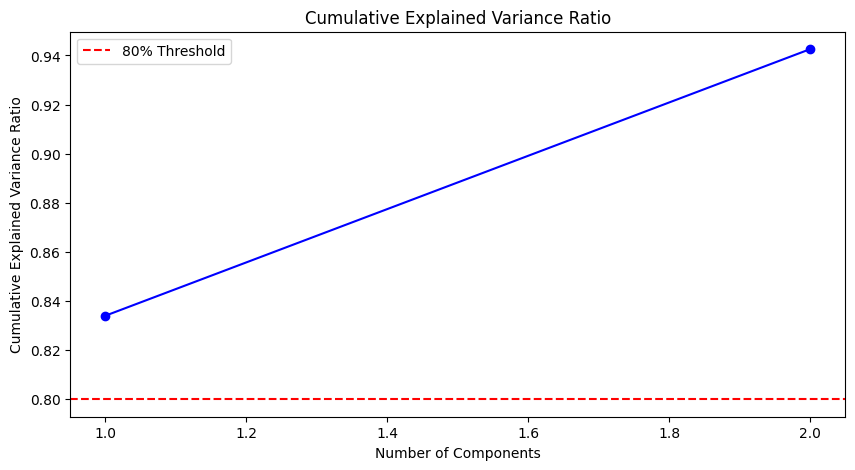

In [21]:
plot_cumulative_variance(pca)

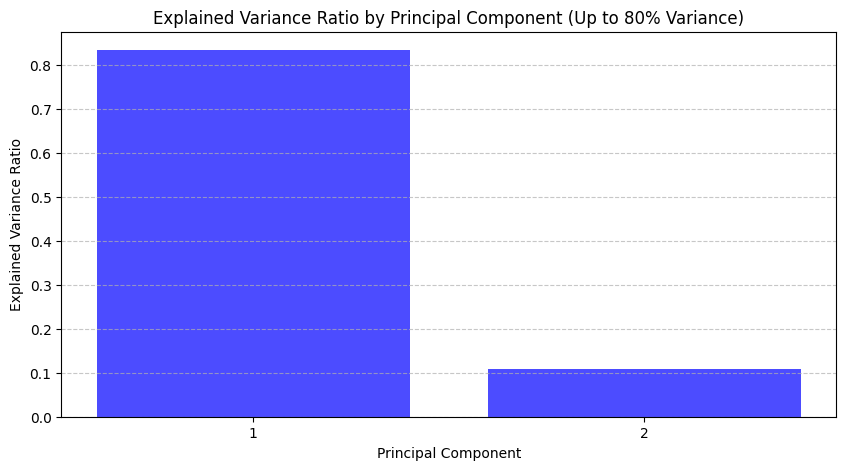

In [22]:
plot_explained_variance(pca, n_components)

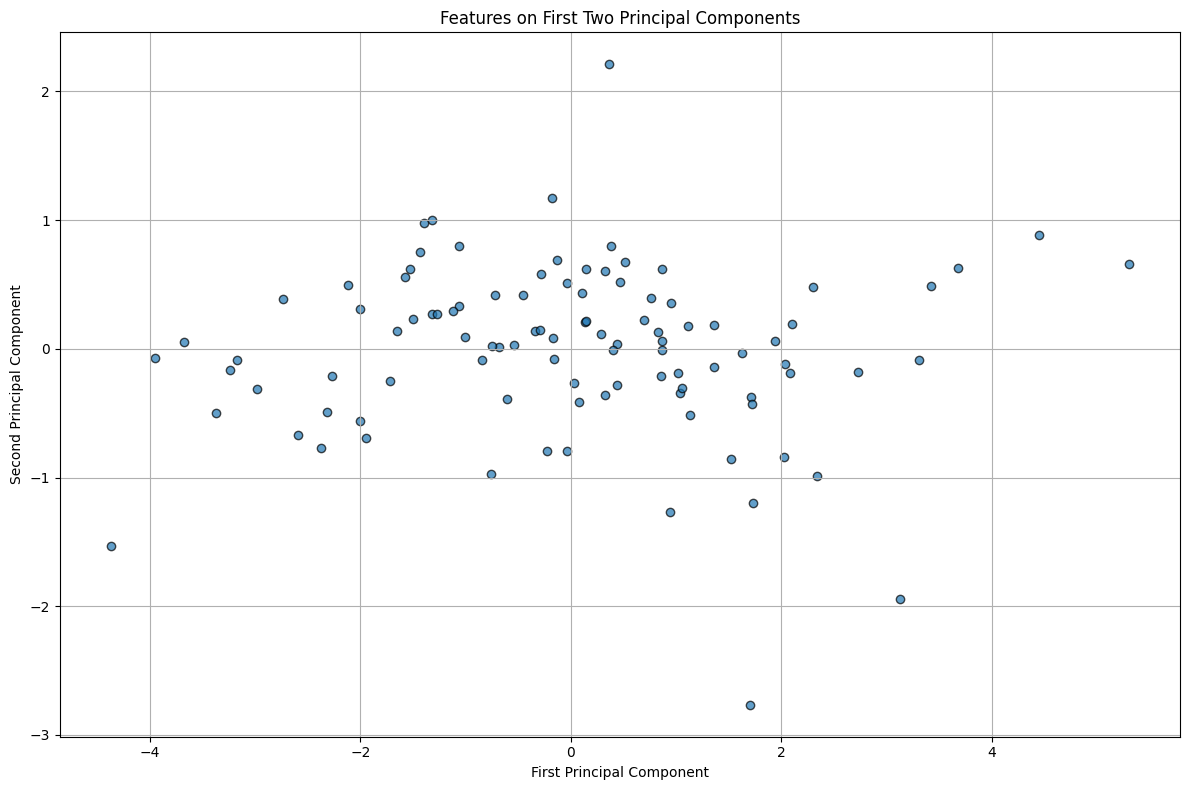

In [23]:
plot_pca_features(pca, X_pca, n_components)

In [24]:
loadings_df = plot_feature_loadings(pca, feature_names, n_components)
loadings_df


,PC1,PC2
r_mean,0.929874,-0.032195
g_mean,0.973561,-0.204174
b_mean,0.941854,-0.256446
w_mean,0.818636,0.574428


In [25]:
loadings_df.sort_values(by="PC1", ascending=False).head(10)

,PC1,PC2
g_mean,0.973561,-0.204174
b_mean,0.941854,-0.256446
r_mean,0.929874,-0.032195
w_mean,0.818636,0.574428



Step 9-12: Performing clustering analysis...


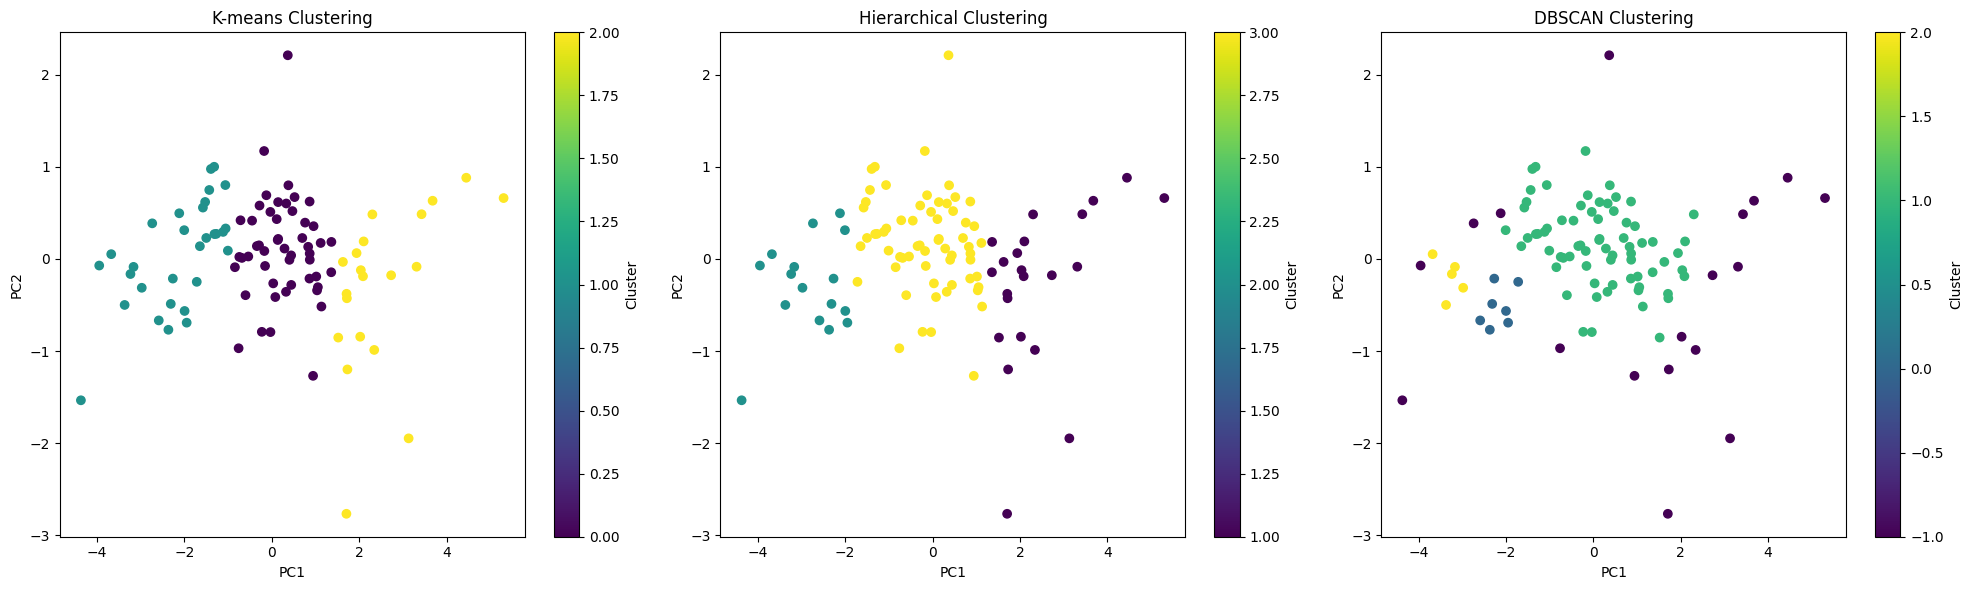

In [26]:
# 9-12. Clustering Analysis
print("\nStep 9-12: Performing clustering analysis...")
plot_clustering_comparison(X_pca, n_components)

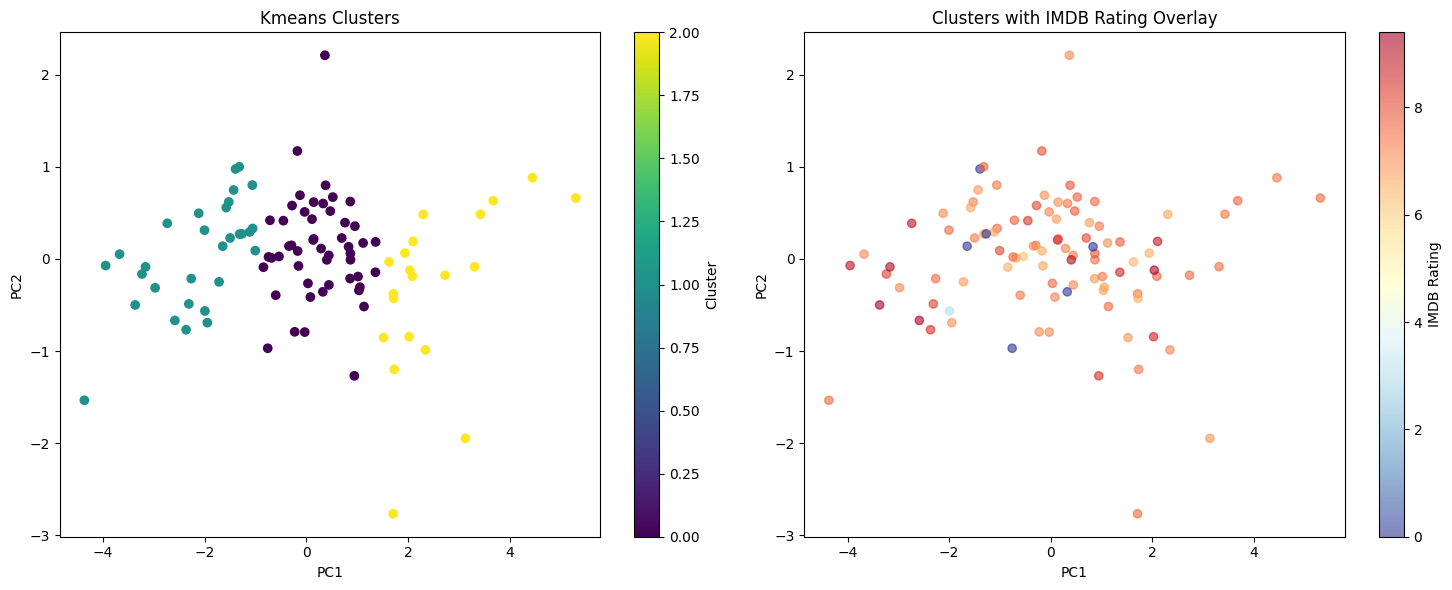


Cluster Statistics for IMDB Rating:
            mean      std  count
Cluster                         
0       6.984000 1.886727     50
1       6.803333 2.590365     30
2       7.470000 0.771942     20

One-way ANOVA test results:
F-statistic: 0.7037
p-value: 0.4973


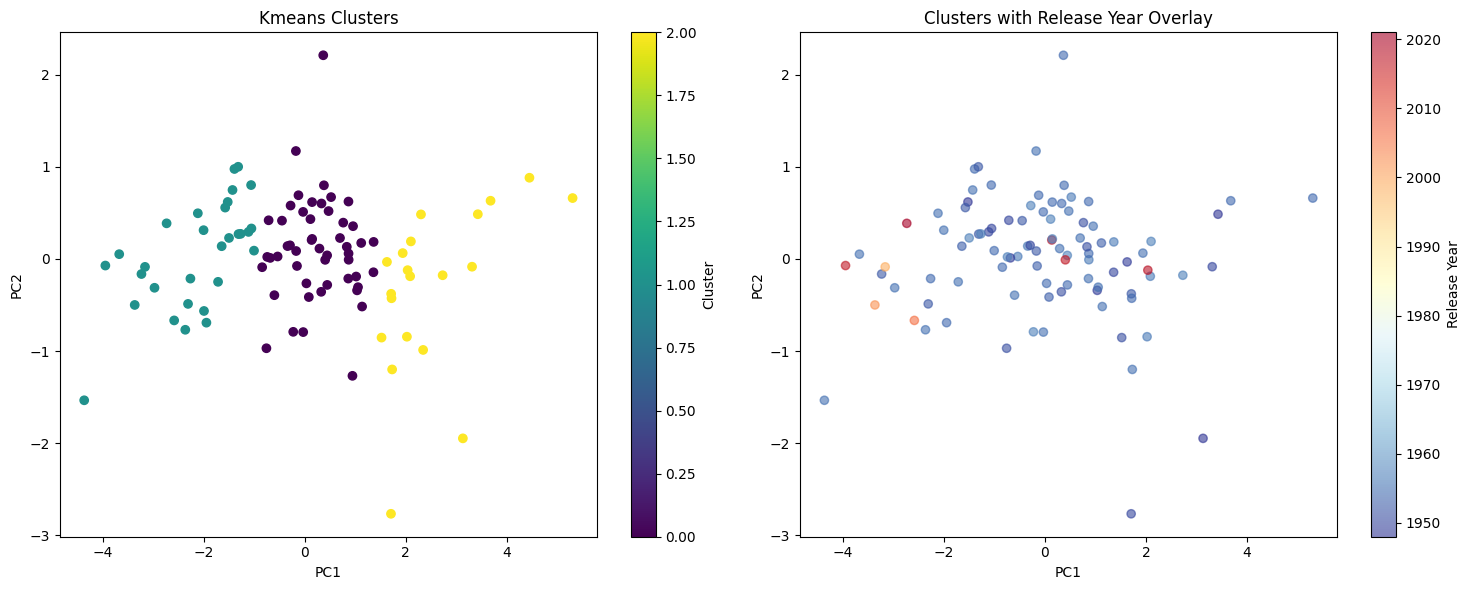


Cluster Statistics for Release Year:
               mean       std  count
Cluster                             
0       1956.583333 13.025071     48
1       1963.103448 21.714618     29
2       1956.705882 16.088679     17

One-way ANOVA test results:
F-statistic: nan
p-value: nan


In [27]:
# Extract year from date_published
imdb_df['year'] = pd.to_datetime(imdb_df['date_published']).dt.year

# Merge feature data with IMDB data
merged_df = pd.merge(feature_df, imdb_df, on='imdb_id')

# Visualize clusters with ratings
plot_clusters_with_metadata(X_pca, merged_df['rating'], 'IMDB Rating')
analyze_clusters_with_metadata(X_pca, merged_df['rating'], 'IMDB Rating')

# Visualize clusters with years
plot_clusters_with_metadata(X_pca, merged_df['year'], 'Release Year')
analyze_clusters_with_metadata(X_pca, merged_df['year'], 'Release Year')

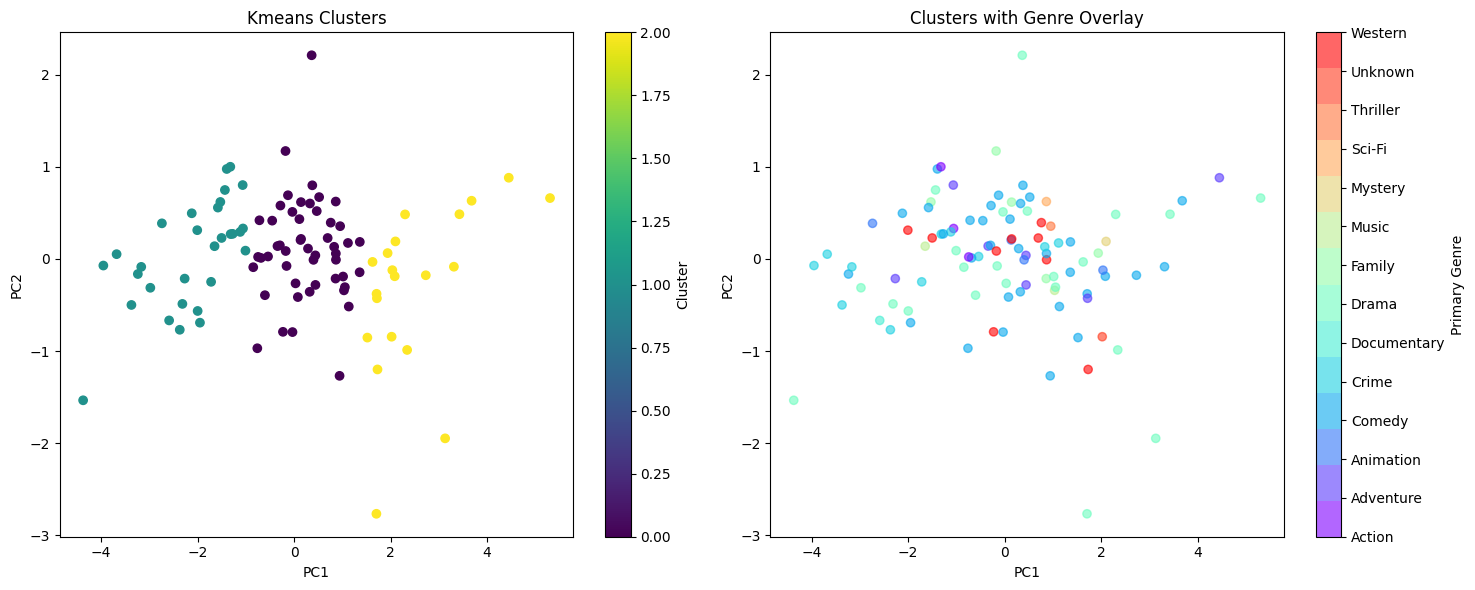


Genre Distribution across Clusters:

Percentage of genres in each cluster:
Genre     Action  Adventure  Animation    Comedy     Crime  Documentary  \
Cluster                                                                   
0       2.000000   6.000000   4.000000 40.000000  6.000000     0.000000   
1       6.670000   6.670000   3.330000 20.000000 26.670000     3.330000   
2       0.000000  10.000000   5.000000 30.000000  0.000000     0.000000   

Genre       Drama   Family    Music  Mystery   Sci-Fi  Thriller  Unknown  \
Cluster                                                                    
0       18.000000 6.000000 2.000000 0.000000 2.000000  2.000000 0.000000   
1       20.000000 3.330000 3.330000 0.000000 0.000000  0.000000 0.000000   
2       35.000000 5.000000 0.000000 5.000000 0.000000  0.000000 5.000000   

Genre     Western  
Cluster            
0       12.000000  
1        6.670000  
2        5.000000  

Genre proportions in each cluster:
            Action  Adventure  

In [28]:
# Visualize clusters with genres
plot_clusters_with_genres(X_pca, merged_df['genres'])
analyze_genre_distribution(X_pca, merged_df['genres'])